# Measuring model uncertainty in classification with MAPIE

This example demonstrates how to use methods from the MAPIE library to measure the uncertainty of a classification model. In addition to the classification, we want to know when the model is uncertain about its prediction. We use a text dataset of news articles sorted into 4 classes : World, Sports,Business, Sci/Tech. 

The dataset is from Xiang Zhang, Junbo Zhao, Yann LeCun. Character-level Convolutional Networks for Text Classification. Advances in Neural Information Processing Systems 28 (NIPS 2015).

This notebook follows:
1. Load and format the data
2. Choose a scikit-learn classifier
3. Use a MAPIE Conformalizer to compute prediction sets
4. Explore the results

## Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import ConfusionMatrixDisplay, precision_score, recall_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

from mapie.classification import SplitConformalClassifier 
from mapie.utils import train_conformalize_test_split
from mapie.metrics.classification import classification_mean_width_score, classification_ssc, classification_coverage_score

## Load data

In this part, we'll just load and format the data.

In [2]:
classes = {'World': 1, 'Sports': 2, 'Business': 3, 'Sci/Tech': 4}
df_train = pd.read_csv('./data/ag-news-classification-dataset/train.csv')
df_test = pd.read_csv('./data/ag-news-classification-dataset/test.csv')
df_train.head()

,Class Index,Title,Description
0,3,Wall St. Bears Claw Back Into the Black (Reuters),"Reuters - Short-sellers, Wall Street's dwindli..."
1,3,Carlyle Looks Toward Commercial Aerospace (Reu...,Reuters - Private investment firm Carlyle Grou...
2,3,Oil and Economy Cloud Stocks' Outlook (Reuters),Reuters - Soaring crude prices plus worries\ab...
3,3,Iraq Halts Oil Exports from Main Southern Pipe...,Reuters - Authorities have halted oil export\f...
4,3,"Oil prices soar to all-time record, posing new...","AFP - Tearaway world oil prices, toppling reco..."


In [3]:
# data split

y = df_train["Class Index"]
df_train["Article"] = df_train["Title"] + " " + df_train["Description"]
X = df_train.drop(['Class Index', 'Title', 'Description'], axis=1)
X = X.squeeze()
X_train, X_conf, y_train, y_conf = train_test_split(X, y, test_size=0.35)

y_test = df_test["Class Index"]
df_test["Article"] = df_test["Title"] + " " + df_test["Description"]
X_test = df_test.drop(['Class Index', 'Title', 'Description'], axis=1)
X_test = X_test.squeeze()

## Training and conformalization

**Exercise 1:**

- Choose a model : This is a text classification dataset, and we want to use scikit-learn estimators because MAPIE is integrated into the sklearn environment. 
- Setup a MAPIE conformalizer with a confidence_level
- Train the model and conformalize it
- Predict : compute the prediction sets on the test set

In [4]:
text_clf = # TODO

confidence_level = # TODO

conf = # TODO




y_pred, y_pred_sets = # TODO

SyntaxError: invalid syntax (560130879.py, line 1)

## Results

First, let's check the performance of our model :
- compute the precision and recall for each class
- plot a confusion matrix

Class  World 
 precision :  0.91  recall :  0.89
Class  Sports 
 precision :  0.95  recall :  0.98
Class  Business 
 precision :  0.87  recall :  0.86
Class  Sci/Tech 
 precision :  0.88  recall :  0.88


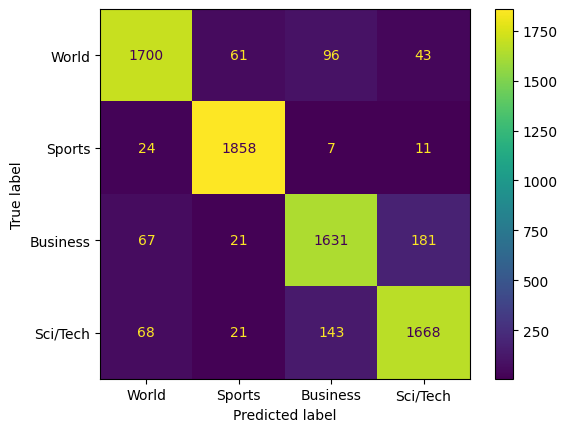

In [ ]:
# check performance
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=list(classes.keys()))
disp.plot()

precisions = precision_score(y_test, y_pred, average=None)
recalls = recall_score(y_test, y_pred, average=None)

for c, i in classes.items():
    print('Class ', c, '\n precision : ', round(precisions[i-1], 2), ' recall : ', round(recalls[i-1], 2))

The performance is statisfactory. Now let's analyse our prediction sets using MAPIE metrics.

- coverage : what percentage of our true class is contained in the prediction set ? It should be at least `1 - confidence_level`
- mean of width of the prediction sets : the size of a prediction sets indicates on the uncertainty of the prediction, a larger size indiactes a greater uncertainty.

In [ ]:
coverage_score = # TODO
mean_width_score = # TODO

print(
f"For a confidence level of {confidence_level}, \n \
the target coverage is {confidence_level}, \n \
and the effective coverage is {round(coverage_score[0], 2)}. \n \
The mean width of the prediction sets is {round(mean_width_score[0], 2)}"
)

For a confidence level of 0.9, 
 the target coverage is 0.9, 
 and the effective coverage is 0.97. 
 The mean width of the prediction sets is 1.44


We reach the target coverage as expected.

The `mean_width_score` is quite low, which indicates a fairly certain model. Howerver, it is more interesting when computed over specific groups, as this help us to understand where the model is uncertain. 
This is what we will do now.

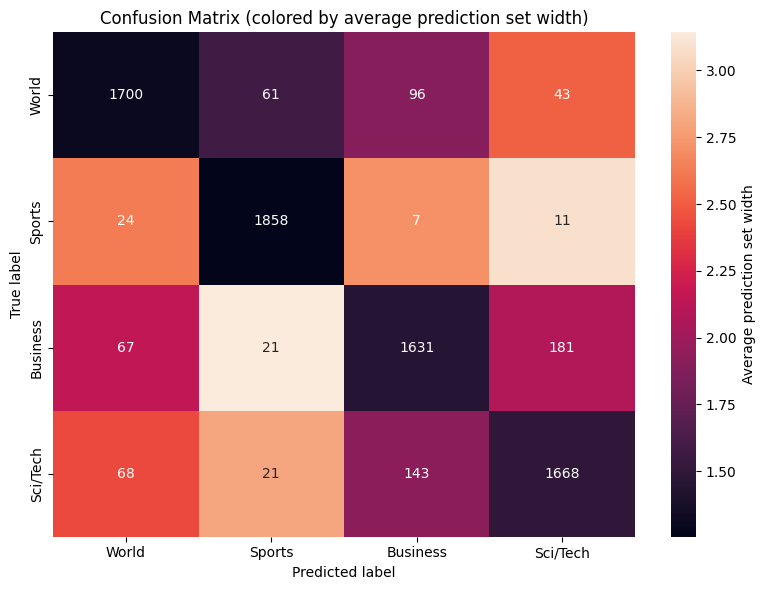

In [ ]:
labels = list(classes.values())
cm = confusion_matrix(y_test, y_pred)
width_matrix = np.full((len(labels), len(labels)), np.nan)

for i, true_label in enumerate(labels):
    for j, pred_label in enumerate(labels):
        mask = (y_test == true_label) & (y_pred == pred_label)
        width_matrix[i, j] = classification_mean_width_score(y_pred_sets[mask,:,:])[0]

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    width_matrix,
    annot=cm,
    fmt="d",
    #cmap="YlOrRd",
    xticklabels=list(classes.keys()),
    yticklabels=list(classes.keys()),
    cbar_kws={"label": "Average prediction set size"},
    ax=ax
)

ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("Confusion Matrix (colored by average prediction set size)")

plt.tight_layout()
plt.show()

This is the same confusion matrix as before, but now the color indicates the mean of the prediction set size. On the diagonal, deep purple corresponds to a mean size of ~1, meaning that, for these examples, there is mostly only one class in the set : the model is very certain. The examples on the diagonal represent those correctly classified by the model. 

When the color is lighter / more red, the mean of prediction set size is between 2 and 3, indicating that there are between 2 and 3 classes in each set : the model is uncertain.

It is clear that most of the time, the model is certain when it is right and uncertain when it is wrong. This is a very important information to have when we predict on new data: based on the computed uncertainty, we can make better decisions with our predictions.

**Examples**

Finally, let's look at some examples of news articles where the prediction sets contain more than one class.

In [ ]:
set_widths = y_pred_sets.sum(axis=1)
large_idx = np.where(set_widths >= 2)[0]

class_names = {v: k for k, v in classes.items()}

df_uncertain = df_test.iloc[large_idx].copy()

df_uncertain["true_class"] = df_uncertain["Class Index"].map(class_names)
df_uncertain["predicted_class"] = [class_names[y_pred[idx]] for idx in large_idx]
df_uncertain["classes_in_set"] = [
    [class_names[c] for c in np.where(y_pred_sets[idx, :, 0])[0] + 1]
    for idx in large_idx
]

df_uncertain = df_uncertain.drop(['Article', 'Class Index'], axis=1)
df_uncertain.head()

,Title,Description,true_class,predicted_class,classes_in_set
2,Ky. Company Wins Grant to Study Peptides (AP),AP - A company founded by a chemistry research...,Sci/Tech,Sci/Tech,"[Business, Sci/Tech]"
3,Prediction Unit Helps Forecast Wildfires (AP),AP - It's barely dawn when Mike Fitzpatrick st...,Sci/Tech,Sports,"[Sports, Business, Sci/Tech]"
4,Calif. Aims to Limit Farm-Related Smog (AP),AP - Southern California's smog-fighting agenc...,Sci/Tech,Sci/Tech,"[World, Business, Sci/Tech]"
8,E-mail scam targets police chief,"Wiltshire Police warns about ""phishing"" after ...",Sci/Tech,Sci/Tech,"[World, Business, Sci/Tech]"
9,"Card fraud unit nets 36,000 cards","In its first two years, the UK's dedicated car...",Sci/Tech,Sci/Tech,"[Business, Sci/Tech]"


By examining at some specific examples we can understand why the model is uncertain. We can then use this information to fine tune the model for example, or to make better decisions based on the predictions.